In [10]:
import torch
from torch import nn
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt

In [11]:
class DivisibleDCN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.layer = nn.Linear(2, 2, True)
        self.projector = nn.Linear(2, 1, False)
    
    def forward(self, x):
        cross_prediction = self.layer(x) / torch.clip(x, min=1.0).float()

        return self.projector(cross_prediction)

In [12]:
ctrPredictor = DivisibleDCN()

ctrPredictor

DivisibleDCN(
  (layer): Linear(in_features=2, out_features=2, bias=True)
  (projector): Linear(in_features=2, out_features=1, bias=False)
)

In [13]:
ctrPredictor(torch.tensor([0, 1]).float())

tensor([-0.0497], grad_fn=<SqueezeBackward4>)

In [14]:
click_counters = torch.randint(low=0, high=1000, size=(1_000_000,))
show_counters = torch.randint(low=0, high=10000, size=(1_000_000,)) + click_counters

click_counters, show_counters

(tensor([894, 779, 937,  ...,  95, 847, 893]),
 tensor([2716, 4794, 1313,  ..., 3459, 8899, 7918]))

In [15]:
optimizer = torch.optim.AdamW(ctrPredictor.parameters(), lr=3e-4, weight_decay=1e-6)

losses = []
for batch_start in tqdm(range(click_counters.size(0) // 100)):
    click_slice = click_counters[batch_start: batch_start+100]
    show_slice = show_counters[batch_start: batch_start+100]

    input_batch = torch.stack([click_slice, show_slice], dim=-1)

    optimizer.zero_grad()
    predicted_ctrs = ctrPredictor(input_batch.float())
    true_ctrs = click_slice.float() / show_slice.float()
    loss = torch.nn.functional.mse_loss(true_ctrs.unsqueeze(-1), predicted_ctrs)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())


  0%|          | 0/10000 [00:00<?, ?it/s]

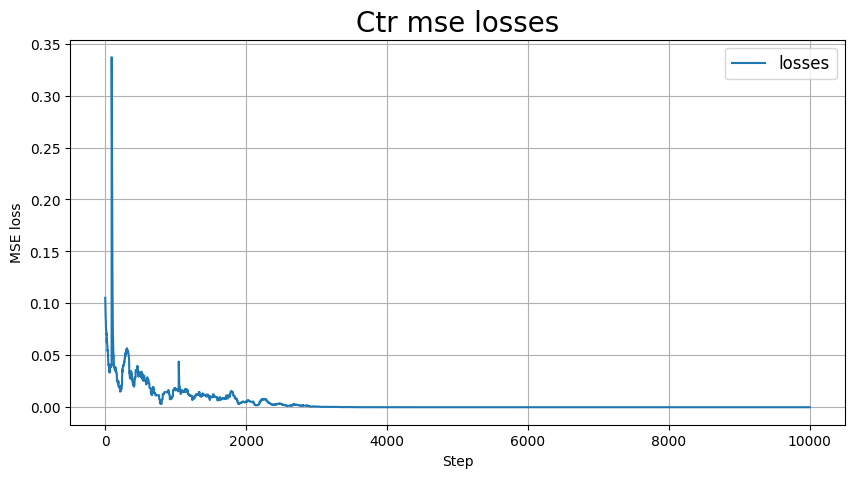

In [16]:
plt.figure(figsize=(10, 5))
plt.title("Ctr mse losses", fontsize=20)
plt.plot(range(click_counters.size(0) // 100), losses, label="losses")
plt.grid(True)
plt.legend(fontsize=12)
plt.xlabel("Step")
plt.ylabel("MSE loss")
plt.show()

# Test

In [17]:
click_counters_test = torch.randint(low=0, high=1000, size=(10,))
show_counters_test = torch.randint(low=0, high=10000, size=(10,)) + click_counters_test

click_counters_test, show_counters_test

(tensor([361, 637,  40, 661, 298, 252, 661, 444, 916, 457]),
 tensor([5829, 5643, 5832, 2215, 3641, 8930, 1414, 5033, 2161,  511]))

In [18]:
truth_ctrs_test = click_counters_test / show_counters_test

ctrPredictor.eval()
with torch.no_grad():
    predicted_ctrs_test = ctrPredictor(torch.stack([click_counters_test, show_counters_test], dim=1).float())

print(f"True ctrs test: {truth_ctrs_test}")
print(f"Pred ctrs test: {predicted_ctrs_test}")

True ctrs test: tensor([0.0619, 0.1129, 0.0069, 0.2984, 0.0818, 0.0282, 0.4675, 0.0882, 0.4239,
        0.8943])
Pred ctrs test: tensor([[0.0621],
        [0.1129],
        [0.0072],
        [0.2983],
        [0.0820],
        [0.0284],
        [0.4673],
        [0.0883],
        [0.4236],
        [0.8941]])


In [22]:
ctrPredictor.layer.weight, ctrPredictor.layer.bias

(Parameter containing:
 tensor([[-5.8537e-01,  2.1116e-05],
         [ 9.5531e-01, -1.5195e-02]], requires_grad=True),
 Parameter containing:
 tensor([-0.2721,  0.4380], requires_grad=True))

In [21]:
ctrPredictor.projector.weight

Parameter containing:
tensor([[-0.0274,  1.0453]], requires_grad=True)